In [ ]:
!pip install -q groq kaggle
import os, re, io, glob, json, time, shutil, subprocess, warnings, traceback
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
warnings.filterwarnings("ignore")

try:
    from google.colab import userdata
    GROQ_API_KEY = userdata.get("GROQ_API_KEY")
except Exception:
    GROQ_API_KEY = os.environ.get("GROQ_API_KEY")
from groq import Groq
client = Groq(api_key=GROQ_API_KEY) if GROQ_API_KEY else None
LLM_MODEL = "openai/gpt-oss-120b"

SEED = 42
CAP_PER_CLASS = 30000            # max training rows per attack class
ARTIFACT_DIR = "/content/sentinelx_artifacts"
os.makedirs(ARTIFACT_DIR, exist_ok=True)
print("Groq API key available:", client is not None)
print("Groq model:", LLM_MODEL)

def llm(system, user, max_tokens=700):
    if client is None:
        return None
    try:
        r = client.chat.completions.create(model=LLM_MODEL, temperature=0, max_tokens=max_tokens,
                                           messages=[{"role": "system", "content": system},
                                                     {"role": "user", "content": user}])
        return r.choices[0].message.content.strip()
    except Exception as e:
        print("LLM error:", e)
        return None

class EnsembleModel:
    """Averages the class probabilities of several LightGBM models (kept at module level so joblib can reload it)."""
    def __init__(self, models):
        self.models = models
        self.classes_ = models[0].classes_
    def predict_proba(self, X):
        return np.mean([m.predict_proba(X) for m in self.models], axis=0)
    def predict(self, X, pred_contrib=False, **kw):
        if pred_contrib:
            return self.models[0].predict(X, pred_contrib=True)   # SHAP drivers come from the first member
        return self.predict_proba(X).argmax(1)

def clean_label(s):
    return re.sub(r"\s+", " ", re.sub(r"[^\x20-\x7E]", "-", str(s))).strip()

Groq API key available: True
Groq model: openai/gpt-oss-120b


In [ ]:
FAMILY = {
    "BENIGN": "Normal traffic", "DoS Hulk": "Denial of Service", "DoS GoldenEye": "Denial of Service",
    "DoS slowloris": "Denial of Service", "DoS Slowhttptest": "Denial of Service", "DDoS": "Denial of Service",
    "PortScan": "Reconnaissance", "FTP-Patator": "Credential attack", "SSH-Patator": "Credential attack",
    "Web Attack - Brute Force": "Credential attack", "Web Attack - XSS": "Web application attack",
    "Web Attack - Sql Injection": "Web application attack", "Bot": "Botnet / C2",
    "Infiltration": "Infiltration", "Heartbleed": "Vulnerability exploit",
}
SEV_BASE = {
    "BENIGN": 0, "PortScan": 40, "DoS slowloris": 55, "DoS Slowhttptest": 55, "Web Attack - XSS": 55,
    "FTP-Patator": 60, "SSH-Patator": 60, "Web Attack - Brute Force": 60, "DoS Hulk": 70, "DoS GoldenEye": 70,
    "DDoS": 75, "Bot": 80, "Web Attack - Sql Injection": 80, "Infiltration": 90, "Heartbleed": 90,
}
EMOJI = {"Critical": "🔴", "High": "🟠", "Medium": "🟡", "Low": "🔵", "Informational": "🟢"}

LABEL_INFO = {
    "BENIGN": {"what": "Normal, legitimate network activity with no sign of attack.",
               "indicators": "Typical durations and packet counts, balanced forward/backward traffic.",
               "actions": []},
    "DoS Hulk": {"what": "An HTTP flood that sends large numbers of unique requests to exhaust a web server.",
                 "indicators": "Very high packet rate towards port 80, many short flows from the same source.",
                 "actions": ["Rate-limit requests per source IP", "Enable a WAF / reverse proxy in front of the web server",
                             "Check web-server CPU, connection counts and access logs", "Block or throttle the offending sources"]},
    "DoS GoldenEye": {"what": "An HTTP DoS tool that uses keep-alive and cache-bypassing requests to tie up a web server.",
                      "indicators": "High request rate and many kept-open HTTP connections to port 80.",
                      "actions": ["Limit concurrent connections per IP", "Tune keep-alive timeouts", "Use a WAF or CDN",
                                  "Review access logs for repeated cache-busting requests"]},
    "DoS slowloris": {"what": "A slow attack that sends partial HTTP requests to hold many connections open.",
                      "indicators": "Long-lived, low-rate flows to the web port with little data transferred.",
                      "actions": ["Set short header/body timeouts", "Limit connections per client IP",
                                  "Put a reverse proxy (e.g., nginx) in front of the server"]},
    "DoS Slowhttptest": {"what": "A slow-HTTP attack (slow headers, body or read) that exhausts server connection slots.",
                         "indicators": "Long-lived connections with very slow data transfer on port 80.",
                         "actions": ["Enforce request timeouts", "Cap connections per IP", "Use a reverse proxy or WAF"]},
    "DDoS": {"what": "A distributed flood from many sources aimed at making a service unavailable.",
             "indicators": "Very high packet/byte rates from many sources to one target.",
             "actions": ["Engage upstream DDoS scrubbing / CDN protection", "Apply rate limits and ACLs",
                         "Contact your ISP", "Scale or fail over the targeted service"]},
    "PortScan": {"what": "Reconnaissance: an attacker probes many ports to discover open services.",
                 "indicators": "Very short flows with 1-3 packets, SYN-only or reset responses, many different destination ports.",
                 "actions": ["Identify and monitor or block the scanning source", "Review which services are exposed",
                             "Tighten firewall rules to the minimum required ports", "Alert on repeated scan behaviour"]},
    "FTP-Patator": {"what": "Brute-force guessing of FTP credentials (port 21).",
                    "indicators": "Many short, repeated login-style sessions to port 21 from one source.",
                    "actions": ["Enable account lockout / fail2ban", "Replace FTP with SFTP and key-based login",
                                "Review logs for any successful login after the failures"]},
    "SSH-Patator": {"what": "Brute-force guessing of SSH credentials (port 22).",
                    "indicators": "Many short, repeated authentication sessions to port 22.",
                    "actions": ["Use key-based authentication and disable passwords", "Enable fail2ban or lockout",
                                "Restrict SSH to trusted IPs / VPN", "Check auth logs for successful logins"]},
    "Bot": {"what": "A compromised host communicating with a botnet command-and-control (C2) server.",
            "indicators": "Periodic, small, regular outbound flows to external hosts.",
            "actions": ["Isolate the suspected host from the network", "Inspect outbound DNS and connection logs",
                        "Run malware / EDR scan and reimage if confirmed", "Reset credentials used on that host"]},
    "Web Attack - Brute Force": {"what": "Credential guessing against a web application login page.",
                                 "indicators": "Many repeated HTTP requests with payloads to the login endpoint on port 80.",
                                 "actions": ["Add rate limiting and CAPTCHA to login", "Enforce MFA and account lockout",
                                             "Review application logs for successful logins"]},
    "Web Attack - XSS": {"what": "Cross-site scripting: injecting malicious scripts through web inputs.",
                         "indicators": "HTTP requests with payloads to the web port, often short flows.",
                         "actions": ["Sanitize and encode user input and output", "Deploy a Content-Security-Policy",
                                     "Enable WAF XSS rules", "Review the affected application code"]},
    "Web Attack - Sql Injection": {"what": "SQL injection: malicious SQL sent through web inputs to read or modify a database.",
                                   "indicators": "HTTP requests with payloads to port 80 targeting a database-backed page.",
                                   "actions": ["Use parameterized queries", "Enable WAF SQLi rules",
                                               "Audit database logs for unusual queries or data access",
                                               "Rotate database credentials if compromise is suspected"]},
    "Infiltration": {"what": "An attacker already inside the network (for example after a malicious download) probing or moving laterally.",
                     "indicators": "Unusual internal flows, internal scanning or unexpected outbound connections from one host.",
                     "actions": ["Isolate the host and start forensic analysis", "Check for lateral movement to other hosts",
                                 "Reset credentials and review recent downloads", "Review outbound connections for data exfiltration"]},
    "Heartbleed": {"what": "Exploitation of the OpenSSL Heartbleed bug (CVE-2014-0160) that leaks server memory.",
                   "indicators": "Long-lived TLS sessions with unusually large amounts of data returned.",
                   "actions": ["Patch OpenSSL immediately", "Revoke and reissue TLS certificates and private keys",
                               "Force password resets for affected services"]},
}

RISK_LEVELS = ["Critical", "High", "Medium", "Low", "Informational"]
def risk_category_arr(score):
    return np.select([score >= 85, score >= 65, score >= 40, score >= 15],
                     ["Critical", "High", "Medium", "Low"], "Informational")

SERVICES = {21: "FTP", 22: "SSH", 23: "Telnet", 25: "SMTP", 53: "DNS", 80: "HTTP", 123: "NTP",
            443: "HTTPS", 445: "SMB", 3306: "MySQL", 3389: "RDP", 8080: "HTTP-alt"}
def compute_risk(P, classes):
    # returns P(malicious), risk score 0-100, and the most likely attack class (benign excluded)
    P64 = np.asarray(P, dtype="float64")
    b = classes.index("BENIGN")
    w = np.array([SEV_BASE.get(c, 50) / 100 for c in classes], dtype="float64"); w[b] = 0.0
    p_mal = np.clip(1 - P64[:, b], 0, 1)
    exp_sev = (P64 * w).sum(1) / np.maximum(p_mal, 1e-9)
    risk = np.clip(100 * p_mal * (0.35 + 0.65 * exp_sev), 0, 100)
    Pa = P64.copy(); Pa[:, b] = -1
    return p_mal, risk, Pa.argmax(1)

print(len(LABEL_INFO), "attack types in the knowledge base")

15 attack types in the knowledge base


In [ ]:
# Download the original CIC-IDS2017 Kaggle dataset using the user's kaggle.json credentials.
# This does NOT require manually downloading the dataset ZIP in a browser.

from pathlib import Path

DATA_DIR = "/content/cic"
KAGGLE_DATASET = "chethuhn/network-intrusion-dataset"
os.makedirs(DATA_DIR, exist_ok=True)

csv_files = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)

if not csv_files:
    from google.colab import files

    kaggle_dir = os.path.expanduser("~/.kaggle")
    os.makedirs(kaggle_dir, exist_ok=True)
    kaggle_json_target = os.path.join(kaggle_dir, "kaggle.json")

    # Reuse credentials already present in Colab; otherwise ask for kaggle.json once.
    possible_sources = [
        "/content/kaggle.json",
        os.path.join(os.getcwd(), "kaggle.json"),
        kaggle_json_target,
    ]
    kaggle_json_source = next((p for p in possible_sources if os.path.isfile(p)), None)

    if kaggle_json_source is None:
        print("Upload your Kaggle API token file named exactly kaggle.json")
        uploaded = files.upload()
        matching_names = [name for name in uploaded if os.path.basename(name) == "kaggle.json"]
        if not matching_names:
            raise FileNotFoundError(
                "kaggle.json was not uploaded. Open Kaggle > Settings > API, generate a token, "
                "and upload the downloaded kaggle.json file."
            )
        kaggle_json_source = matching_names[0]

    if os.path.abspath(kaggle_json_source) != os.path.abspath(kaggle_json_target):
        shutil.copyfile(kaggle_json_source, kaggle_json_target)

    # Validate that the file is a Kaggle API token without printing its secret contents.
    with open(kaggle_json_target, "r", encoding="utf-8") as f:
        kaggle_credentials = json.load(f)
    if not kaggle_credentials.get("username") or not kaggle_credentials.get("key"):
        raise ValueError(
            "kaggle.json must contain non-empty 'username' and 'key' fields. "
            "Generate a fresh token from Kaggle Settings > API."
        )

    os.chmod(kaggle_json_target, 0o600)
    os.environ["KAGGLE_CONFIG_DIR"] = kaggle_dir

    # kaggle CLI was installed in Cell 0.
    print(f"Authenticating with kaggle.json and downloading {KAGGLE_DATASET} ...")
    result = subprocess.run(
        ["kaggle", "datasets", "download", "-d", KAGGLE_DATASET,
         "-p", DATA_DIR, "--unzip"],
        text=True, capture_output=True
    )
    if result.returncode != 0:
        details = (result.stderr or result.stdout or "No details returned by Kaggle CLI").strip()
        raise RuntimeError(
            "Kaggle download failed. Check that kaggle.json is valid and that you can open "
            f"https://www.kaggle.com/datasets/{KAGGLE_DATASET} while signed in.\n\n"
            f"Kaggle CLI output:\n{details}"
        )
    if result.stdout.strip():
        print(result.stdout.strip())

    csv_files = glob.glob(os.path.join(DATA_DIR, "**", "*.csv"), recursive=True)

if not csv_files:
    raise FileNotFoundError(
        f"Kaggle download finished but no CSV files were found under {DATA_DIR}. "
        "Check the downloaded dataset contents before continuing."
    )

print(f"SUCCESS: found {len(csv_files)} CSV file(s) under {DATA_DIR}")
for f in sorted(csv_files):
    print(os.path.basename(f), f"{os.path.getsize(f)/1e6:.0f} MB")


Upload your Kaggle API token file named exactly kaggle.json


Saving kaggle.json to kaggle.json
Authenticating with kaggle.json and downloading chethuhn/network-intrusion-dataset ...
Dataset URL: https://www.kaggle.com/datasets/chethuhn/network-intrusion-dataset
License(s): CC0-1.0
SUCCESS: found 8 CSV file(s) under /content/cic
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv 77 MB
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv 77 MB
Friday-WorkingHours-Morning.pcap_ISCX.csv 58 MB
Monday-WorkingHours.pcap_ISCX.csv 177 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv 83 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv 52 MB
Tuesday-WorkingHours.pcap_ISCX.csv 135 MB
Wednesday-workingHours.pcap_ISCX.csv 225 MB


In [ ]:
frames = []
for f in sorted(glob.glob("/content/cic/**/*.csv", recursive=True)):
    d = pd.read_csv(f, low_memory=False, encoding="latin1")
    d.columns = d.columns.str.strip()
    d["Label"] = d["Label"].map(clean_label)
    d["SourceFile"] = os.path.basename(f)
    num = d.columns.drop(["Label", "SourceFile"])
    d[num] = d[num].apply(pd.to_numeric, errors="coerce")
    d = d.replace([np.inf, -np.inf], np.nan).dropna().drop_duplicates()
    d[num] = d[num].astype("float32")
    frames.append(d)
    print(f"{os.path.basename(f)[:48]:48s} {len(d):>9,} rows")
    del d
data = pd.concat(frames, ignore_index=True); del frames
print(f"\nTOTAL after cleaning: {len(data):,} rows x {data.shape[1]} columns")
print(data["Label"].value_counts())

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv   223,082 rows
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX   213,777 rows
Friday-WorkingHours-Morning.pcap_ISCX.csv          184,044 rows
Monday-WorkingHours.pcap_ISCX.csv                  502,650 rows
Thursday-WorkingHours-Afternoon-Infilteration.pc   252,790 rows
Thursday-WorkingHours-Morning-WebAttacks.pcap_IS   164,179 rows
Tuesday-WorkingHours.pcap_ISCX.csv                 421,626 rows
Wednesday-workingHours.pcap_ISCX.csv               610,492 rows

TOTAL after cleaning: 2,572,640 rows x 80 columns
Label
BENIGN                          2146899
DoS Hulk                         172846
DDoS                             128014
PortScan                          90694
DoS GoldenEye                     10286
FTP-Patator                        5931
DoS slowloris                      5385
DoS Slowhttptest                   5228
SSH-Patator                        3219
Bot                                1948
Web Attack --- Brute Force     

In [ ]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder

feature_cols = [c for c in data.columns if c not in ("Label", "SourceFile")]
le = LabelEncoder().fit(data["Label"]); classes = list(le.classes_); b_idx = classes.index("BENIGN")
y_all = le.transform(data["Label"]); src_all = data["SourceFile"].to_numpy(); X_all = data[feature_cols]

X_rest, X_te, y_rest, y_te, s_rest, s_te = train_test_split(X_all, y_all, src_all, test_size=0.20,
                                                            stratify=y_all, random_state=SEED)
X_tr, X_val, y_tr, y_val, s_tr, s_val = train_test_split(X_rest, y_rest, s_rest, test_size=0.125,
                                                         stratify=y_rest, random_state=SEED)
del data, X_all, X_rest
print(f"train {len(X_tr):,} | validation {len(X_val):,} | test {len(X_te):,}")

rng = np.random.default_rng(SEED)
def capped_idx(y, cap):
    return np.concatenate([rng.choice(np.where(y == c)[0], min(int((y == c).sum()), cap), replace=False)
                           for c in np.unique(y)])
def class_w(y):
    cnt = np.bincount(y, minlength=len(classes))
    return np.minimum((cnt.max() / np.maximum(cnt, 1)) ** 0.5, 20.0)[y]

keep = capped_idx(y_tr, CAP_PER_CLASS)
X_pool, y_pool = X_tr.iloc[keep].reset_index(drop=True), y_tr[keep]
vi = rng.choice(len(X_val), min(len(X_val), 100_000), replace=False)
X_vs, y_vs = X_val.iloc[vi], y_val[vi]                     # natural-distribution validation sample
print("training pool:", len(X_pool), "rows")

LGB_PARAMS = dict(objective="multiclass", n_estimators=500, learning_rate=0.08, num_leaves=63, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, min_child_samples=5, reg_lambda=1.0,
                  random_state=SEED, n_jobs=-1, verbose=-1)
t0 = time.time()
final = lgb.LGBMClassifier(**LGB_PARAMS)
final.fit(X_pool, y_pool, sample_weight=class_w(y_pool), eval_set=[(X_vs, y_vs)],
          callbacks=[lgb.early_stopping(25, verbose=False)])
BEST_N = int(final.best_iteration_ or LGB_PARAMS["n_estimators"])
print(f"final model trained in {time.time()-t0:.0f}s | trees per class: {BEST_N}")

def _q(c, p):
    return float(np.quantile(X_tr[c], p)) if c in X_tr.columns else (1e18 if p > 0.5 else 0.0)
REF = {"pps90": _q("Flow Packets/s", 0.90), "bps90": _q("Flow Bytes/s", 0.90),
       "dur90": _q("Flow Duration", 0.90), "dur10": _q("Flow Duration", 0.10)}

train 1,800,848 | validation 257,264 | test 514,528
training pool: 143931 rows
final model trained in 46s | trees per class: 72


In [ ]:

from sklearn.metrics import f1_score, accuracy_score, roc_auc_score
RUN_CV = True            # set False to skip (saves about 10 minutes); the single final model is then deployed
cv_models, cv_rows = [], []
if RUN_CV:
    n_splits = int(max(2, min(5, np.bincount(y_pool).min())))
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    yv_bin = (y_vs != b_idx).astype(int)
    for k, (tr_i, _) in enumerate(skf.split(X_pool, y_pool), 1):
        m = lgb.LGBMClassifier(**{**LGB_PARAMS, "n_estimators": BEST_N, "random_state": SEED + k})
        m.fit(X_pool.iloc[tr_i], y_pool[tr_i], sample_weight=class_w(y_pool[tr_i]))
        Pv = m.predict_proba(X_vs); pm = 1 - Pv[:, b_idx]
        cv_rows.append({"fold": k, "accuracy": accuracy_score(yv_bin, pm >= 0.5),
                        "f1_malicious": f1_score(yv_bin, pm >= 0.5, zero_division=0), "auc_roc": roc_auc_score(yv_bin, pm)})
        cv_models.append(m); print(f"fold {k}/{n_splits} done")
    cv_df = pd.DataFrame(cv_rows).set_index("fold")
    print(cv_df.round(4)); print("\nmean:", cv_df.mean().round(4).to_dict()); print("std :", cv_df.std().round(4).to_dict())
ens = EnsembleModel(cv_models) if cv_models else None


fold 1/5 done
fold 2/5 done
fold 3/5 done
fold 4/5 done
fold 5/5 done
      accuracy  f1_malicious  auc_roc
fold                                 
1       0.9983        0.9950   0.9999
2       0.9984        0.9952   0.9999
3       0.9984        0.9951   0.9999
4       0.9983        0.9950   0.9999
5       0.9984        0.9952   0.9999

mean: {'accuracy': 0.9984, 'f1_malicious': 0.9951, 'auc_roc': 0.9999}
std : {'accuracy': 0.0, 'f1_malicious': 0.0001, 'auc_roc': 0.0}


TEST SET RESULTS (natural class mix, 300,000 flows)


,accuracy,precision,recall,f1,auc,false_alarm,missed,threshold,multiclass_acc,macro_f1
Single final model,0.9987,0.9931,0.9993,0.9962,0.9999,0.0014,0.0007,0.95,0.998,0.8332
5-fold ensemble,0.9988,0.9935,0.9992,0.9964,0.9999,0.0013,0.0008,0.95,0.998,0.8457


Deployed model: 5-fold ensemble | threshold: 0.95

RISK-SCORE RANKING QUALITY: {'rank_auc': 0.9993, 'avg_precision': 0.9858, 'p_at_100': 0.83, 'p_at_1000': 0.876, 'p_at_10000': 0.9876}
mean risk by true class:


,0
Heartbleed,93.4
Bot,86.4
DDoS,83.7
DoS Hulk,80.5
DoS GoldenEye,80.5
FTP-Patator,74.0
SSH-Patator,74.0
Web Attack --- Sql Injection,71.2
DoS Slowhttptest,70.7
DoS slowloris,70.7



MULTI-CLASS REPORT
                              precision    recall  f1-score   support

                      BENIGN       1.00      1.00      1.00    250131
                         Bot       0.54      1.00      0.70       223
                        DDoS       1.00      1.00      1.00     14959
               DoS GoldenEye       0.98      1.00      0.99      1200
                    DoS Hulk       1.00      1.00      1.00     20293
            DoS Slowhttptest       0.97      0.99      0.98       599
               DoS slowloris       0.98      1.00      0.99       603
                 FTP-Patator       0.99      1.00      0.99       709
                  Heartbleed       1.00      1.00      1.00         1
                Infiltration       1.00      0.67      0.80         6
                    PortScan       0.99      1.00      0.99     10684
                 SSH-Patator       0.95      1.00      0.97       362
  Web Attack --- Brute Force       0.72      0.81      0.77       151

,"Sentinel-X (network flows, CIC-IDS2017)","Paper (Android malware, APK descriptions)"
Accuracy,99.88%,94.05%
Recall (malicious),99.92%,96.10%
Binary F1 (malicious),99.64%,93.54%
5-fold accuracy (mean ± std),99.84% ± 0.00,93.36% ± 0.61
5-fold F1 (mean ± std),99.51% ± 0.01,92.63% ± 0.68
5-fold AUC-ROC (mean ± std),99.99% ± 0.00,97.68% ± 0.32


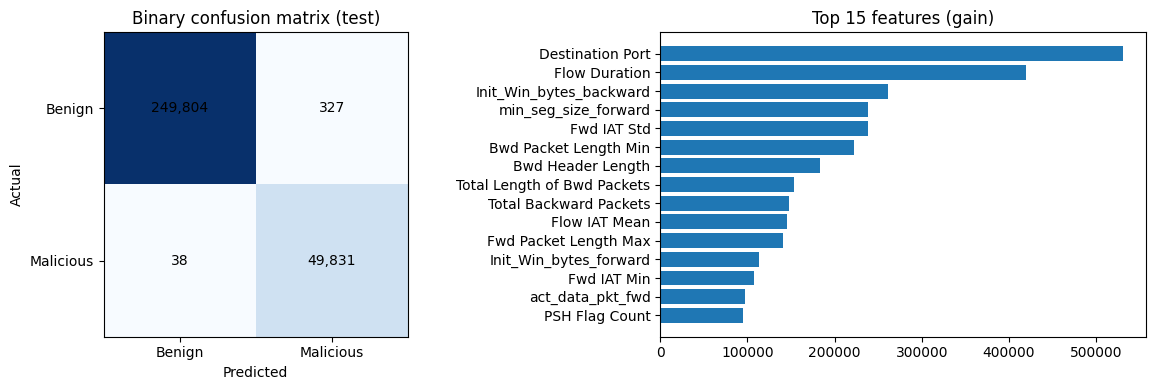

In [ ]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report)

def bin_metrics(P, y, thr=0.5):
    yb = (y != b_idx).astype(int); pm = 1 - P[:, b_idx]; pb = (pm >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb, pb, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(yb, pb), "precision": precision_score(yb, pb, zero_division=0),
            "recall": recall_score(yb, pb, zero_division=0), "f1": f1_score(yb, pb, zero_division=0),
            "auc": roc_auc_score(yb, pm) if len(np.unique(yb)) > 1 else float("nan"),
            "false_alarm": fp / max(1, fp + tn), "missed": fn / max(1, fn + tp)}

def tune_threshold(P, y):                      # choose the decision threshold on the VALIDATION sample only
    yb = (y != b_idx).astype(int); pm = 1 - P[:, b_idx]; best = (0.5, -1.0)
    for t in np.arange(0.05, 0.96, 0.05):
        f = f1_score(yb, pm >= t, zero_division=0)
        if f >= best[1]: best = (float(t), f)
    return best[0]

ti = np.random.default_rng(SEED).choice(len(X_te), min(len(X_te), 300_000), replace=False)
Xe, ye = X_te.iloc[ti], y_te[ti]
cands = {"Single final model": final}
if ens is not None: cands["5-fold ensemble"] = ens
rows, store = {}, {}
for name, mdl in cands.items():
    thr = tune_threshold(mdl.predict_proba(X_vs), y_vs)
    Pt = mdl.predict_proba(Xe); store[name] = (mdl, thr, Pt)
    rows[name] = {**bin_metrics(Pt, ye, thr), "threshold": thr, "multiclass_acc": accuracy_score(ye, Pt.argmax(1)),
                  "macro_f1": f1_score(ye, Pt.argmax(1), average="macro", labels=range(len(classes)), zero_division=0)}
cmp_df = pd.DataFrame(rows).T
print("TEST SET RESULTS (natural class mix, {:,} flows)".format(len(ye))); display(cmp_df.round(4))

best_name = max(rows, key=lambda n: (rows[n]["f1"], rows[n]["macro_f1"]))
deploy, THR, P_dep = store[best_name]
print("Deployed model:", best_name, "| threshold:", round(THR, 2))
M = rows[best_name]

# ranking quality of the RISK SCORE
p_mal, risk, _ = compute_risk(P_dep, classes)
yb = (ye != b_idx).astype(int); order = np.argsort(-risk, kind="stable")
RANK = {"rank_auc": float(roc_auc_score(yb, risk)), "avg_precision": float(average_precision_score(yb, risk))}
for k in (100, 1000, 10000):
    RANK[f"p_at_{k}"] = float(yb[order[:min(k, len(order))]].mean())
print("\nRISK-SCORE RANKING QUALITY:", {k: round(v, 4) for k, v in RANK.items()})
print("mean risk by true class:"); display(pd.Series(risk).groupby(le.inverse_transform(ye)).mean().round(1).sort_values(ascending=False))

print("\nMULTI-CLASS REPORT"); print(classification_report(ye, P_dep.argmax(1), labels=range(len(classes)), target_names=classes, zero_division=0))

cvm = cv_df.mean() if RUN_CV and len(cv_rows) else None; cvs = cv_df.std() if cvm is not None else None
paper = {"Accuracy": "94.05%", "Recall (malicious)": "96.10%", "Binary F1 (malicious)": "93.54%",
         "5-fold accuracy (mean ± std)": "93.36% ± 0.61", "5-fold F1 (mean ± std)": "92.63% ± 0.68",
         "5-fold AUC-ROC (mean ± std)": "97.68% ± 0.32"}
fmt = lambda v: f"{100*v:.2f}%"
ours = {"Accuracy": fmt(M["accuracy"]), "Recall (malicious)": fmt(M["recall"]), "Binary F1 (malicious)": fmt(M["f1"]),
        "5-fold accuracy (mean ± std)": f"{100*cvm['accuracy']:.2f}% ± {100*cvs['accuracy']:.2f}" if cvm is not None else "n/a",
        "5-fold F1 (mean ± std)": f"{100*cvm['f1_malicious']:.2f}% ± {100*cvs['f1_malicious']:.2f}" if cvm is not None else "n/a",
        "5-fold AUC-ROC (mean ± std)": f"{100*cvm['auc_roc']:.2f}% ± {100*cvs['auc_roc']:.2f}" if cvm is not None else "n/a"}
print("\nSAME METRICS, SIDE BY SIDE (different task and data; not a like-for-like benchmark)")
display(pd.DataFrame({"Sentinel-X (network flows, CIC-IDS2017)": ours, "Paper (Android malware, APK descriptions)": paper}))

METRICS = {"test_rows": int(len(ye)), "binary_accuracy": M["accuracy"], "binary_precision": M["precision"],
           "binary_recall": M["recall"], "binary_f1": M["f1"], "roc_auc": M["auc"], "false_alarm_rate": M["false_alarm"],
           "missed_attack_rate": M["missed"], "multiclass_accuracy": M["multiclass_acc"], "macro_f1": M["macro_f1"],
           "threshold": float(THR), "deployed": best_name, **RANK}
if cvm is not None:
    METRICS.update({"cv_acc_mean": float(cvm["accuracy"]), "cv_acc_std": float(cvs["accuracy"]),
                    "cv_f1_mean": float(cvm["f1_malicious"]), "cv_f1_std": float(cvs["f1_malicious"]),
                    "cv_auc_mean": float(cvm["auc_roc"]), "cv_auc_std": float(cvs["auc_roc"])})

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
cm = confusion_matrix(yb, (1 - P_dep[:, b_idx] >= THR).astype(int), labels=[0, 1])
ax[0].imshow(cm, cmap="Blues"); ax[0].set_xticks([0, 1]); ax[0].set_yticks([0, 1])
ax[0].set_xticklabels(["Benign", "Malicious"]); ax[0].set_yticklabels(["Benign", "Malicious"])
ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual"); ax[0].set_title("Binary confusion matrix (test)")
for a in range(2):
    for b in range(2):
        ax[0].text(b, a, f"{cm[a, b]:,}", ha="center", va="center")
imp = pd.Series(final.booster_.feature_importance(importance_type="gain"), index=feature_cols).nlargest(15)[::-1]
ax[1].barh(imp.index, imp.values); ax[1].set_title("Top 15 features (gain)")
plt.tight_layout(); plt.show()

In [ ]:

RUN_STRICT = True
STRICT_TABLE = None
if RUN_STRICT:
    is_fri = lambda arr: np.array(["Friday" in str(s) for s in arr])
    m_tr, m_te = is_fri(s_tr), is_fri(s_te)
    if m_tr.sum() + m_te.sum() == 0 or (~m_tr).sum() == 0:
        print("No Friday files found; skipping.")
    else:
        X_trn, y_trn = X_tr[~m_tr], y_tr[~m_tr]
        X_fri = pd.concat([X_tr[m_tr], X_te[m_te]]); y_fri = np.concatenate([y_tr[m_tr], y_te[m_te]])
        kk = capped_idx(y_trn, 15000)
        sm = lgb.LGBMClassifier(**{**LGB_PARAMS, "n_estimators": min(BEST_N, 150)})
        sm.fit(X_trn.iloc[kk], y_trn[kk], sample_weight=class_w(y_trn[kk]))
        sel = np.random.default_rng(SEED).choice(len(X_fri), min(len(X_fri), 200_000), replace=False)
        Pf = sm.predict_proba(X_fri.iloc[sel]); yf = y_fri[sel]
        pmal_f = 1 - Pf[:, list(sm.classes_).index(b_idx)]
        seen = set(np.unique(y_trn))
        out = []
        for c in np.unique(yf):
            msk = yf == c
            flagged = float((pmal_f[msk] >= 0.5).mean())
            out.append({"Friday class": classes[c], "flows": int(msk.sum()), "seen in training": c in seen,
                        ("flagged as malicious" if c != b_idx else "false-alarm rate"): round(flagged, 4)})
        STRICT_TABLE = pd.DataFrame(out).fillna("-")
        yb_f = (yf != b_idx).astype(int)
        print("Day-held-out (Friday) binary accuracy:", round(float(((pmal_f >= 0.5).astype(int) == yb_f).mean()), 4))
        display(STRICT_TABLE)


Day-held-out (Friday) binary accuracy: 0.7754


,Friday class,flows,seen in training,false-alarm rate,flagged as malicious
0,BENIGN,128796,True,0.0011,-
1,Bot,646,False,-,0.0
2,DDoS,41285,False,-,0.6342
3,PortScan,29273,False,-,0.0083


In [ ]:
bundle = {"model": deploy, "features": feature_cols, "classes": classes, "ref": REF, "metrics": METRICS, "threshold": float(THR)}
joblib.dump(bundle, f"{ARTIFACT_DIR}/sentinelx_model.joblib")

# demo upload file: held-out flows (natural mix + a few of every attack type)
te = X_te.copy(); te["Label"] = le.inverse_transform(y_te)
demo = pd.concat([te.sample(min(8000, len(te)), random_state=SEED)] +
                 [g.sample(min(len(g), 150), random_state=SEED) for _, g in te.groupby("Label")])
demo = demo.sample(frac=1, random_state=SEED).reset_index(drop=True)
DEMO_PATH = f"{ARTIFACT_DIR}/demo_flows.csv"
demo.to_csv(DEMO_PATH, index=False)
demo.to_parquet(f"{ARTIFACT_DIR}/demo_flows.parquet", index=False)
print("Saved model + demo file:", os.listdir(ARTIFACT_DIR), "| demo rows:", len(demo))
# Optional: keep for next time ->  from google.colab import drive; drive.mount('/content/drive'); !cp -r /content/sentinelx_artifacts /content/drive/MyDrive/

Saved model + demo file: ['demo_flows.parquet', 'sentinelx_model.joblib', 'demo_flows.csv'] | demo rows: 9793


In [ ]:
BUNDLE = joblib.load(f"{ARTIFACT_DIR}/sentinelx_model.joblib")
DEMO_PATH = f"{ARTIFACT_DIR}/demo_flows.csv"
APP = {"res": None, "X": None, "summary": None, "kb": None, "file": None}   # single-user demo state

def load_uploaded(path):
    ext = os.path.splitext(str(path))[1].lower()
    if ext == ".parquet":
        return pd.read_parquet(path)
    if ext in (".csv", ".txt"):
        return pd.read_csv(path, low_memory=False, encoding="latin1")
    raise ValueError("Please upload a .csv or .parquet file.")

def colv(X, name):
    return X[name].to_numpy(dtype="float64") if name in X.columns else np.zeros(len(X))

def describe_rows(Xs, ref):
    port, dur = colv(Xs, "Destination Port"), colv(Xs, "Flow Duration")
    fwd, bwd = colv(Xs, "Total Fwd Packets"), colv(Xs, "Total Backward Packets")
    pps, bps = colv(Xs, "Flow Packets/s"), colv(Xs, "Flow Bytes/s")
    syn, ack, rst, psh = (colv(Xs, "SYN Flag Count"), colv(Xs, "ACK Flag Count"),
                          colv(Xs, "RST Flag Count"), colv(Xs, "PSH Flag Count"))
    out = []
    for i in range(len(Xs)):
        p = int(port[i]); svc = SERVICES.get(p)
        d = []
        if pps[i] >= ref["pps90"]: d.append("very high packet rate")
        if bps[i] >= ref["bps90"]: d.append("high bandwidth")
        if dur[i] >= ref["dur90"]: d.append("long-lived connection")
        if dur[i] <= ref["dur10"] and fwd[i] <= 3: d.append("very short probe-like flow with few packets")
        if bwd[i] == 0: d.append("no server response (one-way)")
        if rst[i] > 0: d.append("connection resets")
        if syn[i] > 0 and ack[i] == 0: d.append("SYN-only (half-open)")
        if psh[i] > 0 and svc in ("HTTP", "HTTPS", "HTTP-alt"): d.append("web request payload")
        if svc in ("FTP", "SSH", "Telnet", "RDP") and fwd[i] >= 5 and dur[i] < 5e6: d.append("repeated login-style session")
        tag = f"port {p}" + (f" ({svc})" if svc else "")
        out.append(tag + "; " + ("; ".join(d) if d else "no unusual traffic indicators"))
    return out

def score_flows(raw, bundle, progress=None):
    model, features, classes, ref = bundle["model"], bundle["features"], bundle["classes"], bundle["ref"]
    raw = raw.copy(); raw.columns = raw.columns.astype(str).str.strip()
    true_label = raw["Label"].map(clean_label).to_numpy() if "Label" in raw.columns else None
    present = [c for c in features if c in raw.columns]
    if len(present) < 0.6 * len(features):
        raise ValueError(f"The file has only {len(present)} of the {len(features)} expected CIC-IDS2017 feature columns.")
    X = raw.reindex(columns=features).apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    bad_rows = int(X[present].isna().any(axis=1).sum())
    X = X.fillna(0).astype("float32").reset_index(drop=True)
    n = len(X)
    P = np.empty((n, len(classes)), dtype="float32")
    CH = 100_000
    for s in range(0, n, CH):
        P[s:s + CH] = model.predict_proba(X.iloc[s:s + CH])
        if progress: progress(0.1 + 0.5 * min(1.0, (s + CH) / n), "Scoring flows with the ML model ...")

    thr = float(bundle.get("threshold", 0.5))
    p_mal, risk, best = compute_risk(P, classes)
    cls_arr = np.array(classes)
    is_mal = p_mal >= thr
    ptype = np.where(is_mal, cls_arr[best], "BENIGN")

    if progress: progress(0.65, "Writing explanations ...")
    expl = np.full(n, "Looks like normal traffic; no attack indicators.", dtype=object)
    sel = np.where((risk >= 15) | is_mal)[0]
    desc = describe_rows(X.iloc[sel], ref)
    for j, i in enumerate(sel):
        t = cls_arr[best[i]]; info = LABEL_INFO.get(t, {})
        if is_mal[i]:
            expl[i] = (f"{t} ({FAMILY.get(t, '?')}): the model is {p_mal[i]:.0%} sure this flow is malicious. "
                       f"Indicators: {desc[j]}. {info.get('what', '')}")
        else:
            expl[i] = (f"Mostly normal-looking, but the model sees a {p_mal[i]:.0%} chance of {t}. "
                       f"Indicators: {desc[j]}.")
    res = pd.DataFrame({
        "Record ID": np.arange(n),
        "Rank": pd.Series(risk).rank(ascending=False, method="first").astype(int).to_numpy(),
        "Dst Port": colv(X, "Destination Port").astype(int),
        "Predicted Type": ptype,
        "Family": [FAMILY.get(t, "?") for t in ptype],
        "P(malicious)": np.round(p_mal, 4),
        "Prediction": np.where(is_mal, "Malicious", "Benign"),
        "Risk Score": np.round(risk, 1),
        "Risk Category": risk_category_arr(risk),
        "Explanation": expl,
        "Top Drivers": "",
    })
    if true_label is not None:
        res["True Label"] = true_label
    return res, X, best, bad_rows

def add_drivers(res, X, best, bundle, k=300):
    features = bundle["features"]; F = len(features)
    top = res["Risk Score"].nlargest(k).index.to_numpy()
    top = top[res.loc[top, "Risk Score"].to_numpy() >= 15]
    if len(top) == 0:
        return res
    contrib = bundle["model"].predict(X.iloc[top], pred_contrib=True)
    drivers = []
    for r, i in enumerate(top):
        c = int(best[i])
        block = contrib[c][r, :F] if isinstance(contrib, list) else contrib[r, c * (F + 1): c * (F + 1) + F]
        idx = np.argsort(-np.abs(block))[:3]
        drivers.append("; ".join(f"{features[j]}={X.iloc[i, j]:.4g} ({'supports' if block[j] > 0 else 'opposes'})" for j in idx))
    res.loc[top, "Top Drivers"] = drivers
    return res
print("Scoring functions ready.")

Scoring functions ready.


In [ ]:
def md_table(d):
    cols = list(d.columns)
    lines = ["| " + " | ".join(map(str, cols)) + " |", "|" + "---|" * len(cols)]
    for _, r in d.iterrows():
        lines.append("| " + " | ".join(str(v) for v in r.values) + " |")
    return "\n".join(lines)

def build_summary(res):
    n = len(res); mal = res["Prediction"].eq("Malicious"); n_mal = int(mal.sum())
    cats = res["Risk Category"].value_counts().reindex(RISK_LEVELS).fillna(0).astype(int)
    atk = res.loc[mal, "Predicted Type"].value_counts()
    ports = res.loc[mal, "Dst Port"].value_counts().head(8)
    top10 = res.nlargest(10, "Risk Score")
    rs = res["Risk Score"]
    by_type = (res[mal].groupby("Predicted Type")["Risk Score"].agg(["count", "mean", "max"])
               .sort_values("count", ascending=False).round(1))

    pct = lambda a: f"{100 * a / max(n, 1):.2f}%"
    over = [f"DATASET OVERVIEW: {n:,} network flows analyzed. {n_mal:,} ({pct(n_mal)}) predicted malicious, "
            f"{n - n_mal:,} ({pct(n - n_mal)}) benign.",
            "RISK CATEGORIES: " + ", ".join(f"{k} {v:,} ({pct(v)})" for k, v in cats.items()) + ".",
            f"RISK SCORE STATISTICS: mean {rs.mean():.1f}, median {rs.median():.1f}, 95th percentile {rs.quantile(.95):.1f}, max {rs.max():.1f}.",
            "ATTACK DISTRIBUTION (malicious flows by predicted type): " +
            (", ".join(f"{k} {v:,} ({pct(v)})" for k, v in atk.items()) or "none") + ".",
            "TOP DESTINATION PORTS among malicious flows: " + (", ".join(f"{p} ({c:,})" for p, c in ports.items()) or "none") + ".",
            "TOP 10 HIGHEST-RISK RECORDS: " + "; ".join(
                f"Record {r['Record ID']} ({r['Predicted Type']}, risk {r['Risk Score']}, {r['Risk Category']}, port {r['Dst Port']})"
                for _, r in top10.iterrows()) + "."]
    agree = None
    if "True Label" in res.columns:
        tl = res["True Label"]
        bin_acc = ((tl != "BENIGN") == mal).mean(); type_acc = (tl == res["Predicted Type"]).mean()
        agree = (bin_acc, type_acc)
        over.append(f"AGREEMENT WITH THE FILE'S OWN LABELS: benign/malicious {100*bin_acc:.1f}%, exact attack type {100*type_acc:.1f}%.")

    md_ = [f"## 📊 Dataset summary\n**{n:,}** flows analyzed | **{n_mal:,}** malicious ({pct(n_mal)}) | **{n - n_mal:,}** benign",
           f"\n**Risk score:** mean {rs.mean():.1f} | median {rs.median():.1f} | 95th percentile {rs.quantile(.95):.1f} | max {rs.max():.1f}",
           "\n### Risk categories\n" + md_table(pd.DataFrame({"Category": cats.index, "Records": [f"{v:,}" for v in cats.values],
                                                              "Share": [pct(v) for v in cats.values]})),
           "\n### Attack distribution (malicious flows)\n" +
           (md_table(by_type.reset_index().rename(columns={"Predicted Type": "Attack type", "count": "Records",
                                                           "mean": "Avg risk", "max": "Max risk"})) if len(by_type) else "No malicious flows found."),
           "\n### Top destination ports (malicious)\n" + (", ".join(f"**{p}** ({c:,})" for p, c in ports.items()) or "none"),
           "\n### 🚨 Highest-risk records\n" + md_table(top10[["Rank", "Record ID", "Dst Port", "Predicted Type", "Risk Score", "Risk Category"]])]
    if agree:
        md_.append(f"\n### Check against the file's labels\nBenign/malicious agreement **{100*agree[0]:.1f}%**, exact attack type **{100*agree[1]:.1f}%**.")
    return {"overview_text": "\n".join(over), "markdown": "\n".join(md_), "cats": cats, "atk": atk, "n": n, "n_mal": n_mal}

def make_figs(res):
    f1, a1 = plt.subplots(figsize=(5.5, 3.6))
    a1.hist(res["Risk Score"], bins=40, color="#2b6cb0"); a1.set_yscale("log")
    a1.set_xlabel("Risk score"); a1.set_ylabel("Records (log)"); a1.set_title("Risk score distribution"); f1.tight_layout()
    f2, a2 = plt.subplots(figsize=(5.5, 3.6))
    atk = res.loc[res["Prediction"] == "Malicious", "Predicted Type"].value_counts()[::-1]
    if len(atk): a2.barh(atk.index, atk.values, color="#c53030"); a2.set_xscale("log")
    a2.set_title("Attack distribution (malicious)"); a2.set_xlabel("Records (log)"); f2.tight_layout()
    f3, a3 = plt.subplots(figsize=(5.5, 3.6))
    cats = res["Risk Category"].value_counts().reindex(RISK_LEVELS).fillna(0)
    a3.bar(cats.index, cats.values, color=["#9b2c2c", "#dd6b20", "#d69e2e", "#3182ce", "#38a169"]); a3.set_yscale("log")
    a3.set_title("Records per risk category"); a3.tick_params(axis="x", rotation=20); f3.tight_layout()
    plt.close("all")
    return f1, f2, f3
print("Summary functions ready.")

Summary functions ready.


In [ ]:
from sentence_transformers import SentenceTransformer
_embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
def embed_texts(texts):
    return _embedder.encode(texts, batch_size=128, normalize_embeddings=True, show_progress_bar=False).astype("float32")
print("Embedding model ready.")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model ready.


In [ ]:
!pip install -q faiss-cpu rank-bm25
import re
import numpy as np
import faiss
from rank_bm25 import BM25Okapi

def tok(s):
    return re.findall(r"[a-z0-9]+", str(s).lower())

def rrf(rank_lists, k=60):
    sc = {}
    for lst in rank_lists:
        for r, d in enumerate(lst):
            sc[d] = sc.get(d, 0.0) + 1.0 / (k + r + 1)
    return sorted(sc.items(), key=lambda x: -x[1])

class KB:
    def __init__(self, docs):
        self.docs = docs
        texts = [d["text"] for d in docs]
        self.bm25 = BM25Okapi([tok(t) for t in texts])
        E = embed_texts(texts)
        self.index = faiss.IndexFlatIP(E.shape[1]); self.index.add(E)
    def search(self, q, k=8, pool=40):
        sc = self.bm25.get_scores(tok(q))
        bm = [int(i) for i in np.argsort(-sc)[:pool] if sc[i] > 0]
        _, I = self.index.search(embed_texts([q]), min(pool, len(self.docs)))
        dn = [int(i) for i in I[0]]
        return [self.docs[i] for i, _ in rrf([bm, dn])[:k]]

REC_COLS = ["Flow Duration", "Total Fwd Packets", "Total Backward Packets", "Flow Packets/s", "Flow Bytes/s",
            "SYN Flag Count", "ACK Flag Count", "RST Flag Count"]

def record_doc(res, X, i):
    r = res.iloc[i]
    feats = ", ".join(f"{c}={X.iloc[i][c]:.4g}" for c in REC_COLS if c in X.columns)
    t = (f"Record {r['Record ID']} | Risk rank {r['Rank']} of {len(res):,} | Risk {r['Risk Score']} ({r['Risk Category']}) | Predicted {r['Predicted Type']} "
         f"({r['Prediction']}, P(malicious) {r['P(malicious)']:.0%}) | Dst port {r['Dst Port']} | {r['Explanation']}")
    if r["Top Drivers"]:
        t += f" | Top drivers: {r['Top Drivers']}"
    return {"id": f"REC:{r['Record ID']}", "title": f"Record {r['Record ID']}", "text": t + f" | Features: {feats}"}

def build_docs(res, X, summary):
    docs = [{"id": "OVERVIEW", "title": "Dataset overview", "text": summary["overview_text"]}]
    mal = res[res["Prediction"] == "Malicious"]
    for t, g in mal.groupby("Predicted Type"):
        info = LABEL_INFO.get(t, {})
        cats = g["Risk Category"].value_counts().to_dict()
        ports = g["Dst Port"].value_counts().head(5).to_dict()
        top3 = g.nlargest(3, "Risk Score")
        docs.append({"id": f"TYPE:{t}", "title": f"Attack type {t}", "text":
            f"ATTACK TYPE SUMMARY {t} ({FAMILY.get(t, '?')}): {len(g):,} records ({100*len(g)/len(res):.2f}% of all flows). "
            f"Average risk {g['Risk Score'].mean():.1f}, max {g['Risk Score'].max():.1f}. Risk categories: {cats}. "
            f"Top destination ports: {ports}. Highest-risk records: " +
            ", ".join(f"Record {r['Record ID']} (risk {r['Risk Score']})" for _, r in top3.iterrows()) +
            f". What it is: {info.get('what', '')} Typical indicators: {info.get('indicators', '')} "
            f"Recommended actions: {'; '.join(info.get('actions', [])) or 'none'}."})
    for c in RISK_LEVELS:
        g = res[res["Risk Category"] == c]
        if len(g) == 0:
            continue
        types = g["Predicted Type"].value_counts().head(5).to_dict()
        top5 = g.nlargest(5, "Risk Score")
        docs.append({"id": f"CATEGORY:{c}", "title": f"Risk category {c}", "text":
            f"RISK CATEGORY {c}: {len(g):,} records ({100*len(g)/len(res):.2f}%). Most common predicted types: {types}. "
            f"Top records: " + ", ".join(f"Record {r['Record ID']} ({r['Predicted Type']}, risk {r['Risk Score']}, port {r['Dst Port']})"
                                         for _, r in top5.iterrows()) + "."})
    for p, cnt in res.loc[res["Prediction"] == "Malicious", "Dst Port"].value_counts().head(15).items():
        g = res[res["Dst Port"] == p]
        docs.append({"id": f"PORT:{p}", "title": f"Port {p}", "text":
            f"PORT {p} ({SERVICES.get(int(p), 'other')}): {len(g):,} flows, {int((g['Prediction'] == 'Malicious').sum()):,} malicious, "
            f"average risk {g['Risk Score'].mean():.1f}. Predicted types on this port: {g['Predicted Type'].value_counts().head(5).to_dict()}."})
    sel = set(int(i) for i in res["Risk Score"].nlargest(500).index)
    for t, g in res.groupby("Predicted Type"):
        sel |= set(int(i) for i in g["Risk Score"].nlargest(25).index)
    sel |= set(int(i) for i in np.random.default_rng(0).choice(len(res), min(len(res), 150), replace=False))
    for i in sorted(sel):
        docs.append(record_doc(res, X, i))
    return docs
print("RAG knowledge-base builder ready.")

RAG knowledge-base builder ready.


In [ ]:
def top_table(res, k=50):
    return res.nlargest(k, "Risk Score")[["Rank", "Record ID", "Dst Port", "Predicted Type", "P(malicious)", "Risk Score",
                                          "Risk Category", "Explanation", "Top Drivers"]]

def analyze_file(path, progress=None):
    P_ = (lambda f, d: progress(f, desc=d)) if progress else (lambda f, d: None)
    t0 = time.time()
    P_(0.02, "Reading file ...")
    raw = load_uploaded(path)
    res, X, best, bad = score_flows(raw, BUNDLE, progress=(lambda f, d: P_(f, d)))
    P_(0.75, "Computing SHAP drivers for top-risk records ...")
    res = add_drivers(res, X, best, BUNDLE)
    P_(0.82, "Building dataset summary ...")
    summary = build_summary(res); figs = make_figs(res)
    P_(0.88, "Indexing records for the chatbot (BM25 + FAISS) ...")
    docs = build_docs(res, X, summary)
    kb = KB(docs)
    out_path = os.path.join(ARTIFACT_DIR, "sentinelx_risk_table.csv")
    res.to_csv(out_path, index=False)
    APP.update({"res": res, "X": X, "summary": summary, "kb": kb, "file": os.path.basename(str(path))})
    note = f" ({bad:,} rows had invalid values replaced by 0)" if bad else ""
    status = (f"✅ Processed **{len(res):,}** records from `{APP['file']}` in {time.time()-t0:.0f}s{note}. "
              f"Chatbot index: {len(docs):,} documents.")
    return status, summary["markdown"], figs, top_table(res), out_path

# quick test on the demo file
status, smry, figs, tbl, out = analyze_file(DEMO_PATH)
print(status); tbl.head(5)

✅ Processed **9,793** records from `demo_flows.csv` in 25s. Chatbot index: 925 documents.


,Rank,Record ID,Dst Port,Predicted Type,P(malicious),Risk Score,Risk Category,Explanation,Top Drivers
2345,4,2345,444,Infiltration,0.9998,93.5,Critical,Infiltration (Infiltration): the model is 100%...,Total Length of Fwd Packets=1.467e+04 (support...
8120,3,8120,444,Infiltration,0.9999,93.5,Critical,Infiltration (Infiltration): the model is 100%...,Total Length of Fwd Packets=2.321e+06 (support...
9400,1,9400,444,Infiltration,1.0000,93.5,Critical,Infiltration (Infiltration): the model is 100%...,Destination Port=444 (supports); Min Packet Le...
9562,2,9562,444,Infiltration,1.0000,93.5,Critical,Infiltration (Infiltration): the model is 100%...,Total Length of Fwd Packets=7.853e+05 (support...
3902,5,3902,444,Heartbleed,0.9995,93.4,Critical,Heartbleed (Vulnerability exploit): the model ...,Bwd Packet Length Max=1.593e+04 (supports); Fw...


In [ ]:
REWRITE_SYSTEM = (
    "Rewrite the user's question as ONE concise search query for a knowledge base containing: a dataset overview, "
    "per-attack-type summaries, per-risk-category summaries, per-port summaries, and individual network-flow records "
    "(predicted attack type, risk score, risk category, destination port, explanation). Keep every technical term, "
    "number, port and attack name from the question, and add likely attack-type names and risk category words. "
    "Output only the query.")
QUERY_RULES = [
    (r"flood|hammer|overwhelm|denial|dos", "DoS Hulk DoS GoldenEye DDoS Denial of Service"),
    (r"scan|probe|recon", "PortScan Reconnaissance"),
    (r"password|brute|guess|login|credential", "FTP-Patator SSH-Patator Credential attack Web Attack - Brute Force"),
    (r"sql|xss|web attack|injection", "Web Attack - Sql Injection Web Attack - XSS Web application attack"),
    (r"bot|c2|command and control", "Bot Botnet"),
    (r"worst|top|highest|dangerous|urgent|priorit", "Critical High highest risk records"),
]
def rewrite_chat_query(q):
    out = llm(REWRITE_SYSTEM, q, max_tokens=100)
    if out:
        out = out.strip().strip('"').split("\n")[0]
        miss = [t for t in re.findall(r"\b(?:[A-Z]{2,}[a-z]*|\d+)\b", q) if t.lower() not in out.lower()]
        return out + (" " + " ".join(miss) if miss else "")
    extra = [e for p, e in QUERY_RULES if re.search(p, q, re.I)]
    return (q + " " + " ".join(extra)).strip()

ANSWER_SYSTEM = (
    "You are Sentinel-X, a cybersecurity analyst assistant. Answer ONLY from the CONTEXT (dataset overview, risk "
    "statistics and supporting records produced by an ML model on the user's uploaded file). Cite sources using their "
    "bracketed IDs, for example [OVERVIEW], [TYPE:DoS Hulk], [REC:123]. Quote exact numbers from the context; never "
    "invent records, counts or scores. If the context does not contain the answer, say what is missing and suggest "
    "how the user could look it up (for example the Risk table tab). Be concise and well structured. Remember: risk "
    "scores and predictions come from a model and are not proof of an attack.")

def _norm_hist(history):
    turns = []
    for h in history or []:
        if isinstance(h, dict):
            c = h.get("content")
            if isinstance(c, list):
                c = " ".join(x.get("text", "") if isinstance(x, dict) else str(x) for x in c)
            turns.append((h.get("role", "user"), str(c)))
        elif isinstance(h, (list, tuple)) and len(h) == 2:
            turns += [("user", str(h[0])), ("assistant", str(h[1]))]
    return turns[-6:]

def chat_answer_full(question, history=None):
    kb = APP["kb"]
    q2 = rewrite_chat_query(question)
    hits = kb.search(q2, k=8)
    ctx_docs = [kb.docs[0]] + [d for d in hits if d["id"] != "OVERVIEW"]
    context = "\n\n".join(f"[{d['id']}] {d['text']}" for d in ctx_docs)
    hist = "\n".join(f"{r}: {c}" for r, c in _norm_hist(history))
    answer = llm(ANSWER_SYSTEM, f"CONVERSATION SO FAR:\n{hist}\n\nCONTEXT:\n{context}\n\nQUESTION: {question}", max_tokens=700)
    if answer is None:
        answer = ("*(Groq LLM is unavailable (check the API key, model ID, or API error above). Showing the most relevant retrieved evidence instead.)*\n\n" +
                  "\n".join(f"- **[{d['id']}]** {d['text'][:350]}" for d in ctx_docs[:5]))
    return answer, ctx_docs, q2

def chat_answer(question, history=None):
    if APP["kb"] is None:
        return "Please upload a file and click **Analyze** in the first tab, then ask me about the results."
    answer, ctx_docs, q2 = chat_answer_full(question, history)
    srcs = ", ".join(f"`{d['id']}`" for d in ctx_docs)
    return f"{answer}\n\n---\n*Search query used: {q2}*  \n*Sources: {srcs}*"

for q in ["How many Critical records are there?", "What is the most dangerous attack in this file?"]:
    print("Q:", q); print(chat_answer(q)[:700]); print("-" * 60)

Q: How many Critical records are there?
There are **161 records** classified as **Critical** (1.64 % of the 9,793 flows)【OVERVIEW】【CATEGORY:Critical】.

---
*Search query used: How many Critical records are there?*  
*Sources: `OVERVIEW`, `CATEGORY:Critical`, `CATEGORY:Low`, `CATEGORY:Informational`, `CATEGORY:High`, `CATEGORY:Medium`, `TYPE:PortScan`, `TYPE:Heartbleed`, `TYPE:Infiltration`*
------------------------------------------------------------
Q: What is the most dangerous attack in this file?
The attack type with the highest predicted risk in this file is **Infiltration**.  

- All four Infiltration records have the maximum risk score of **93.5**, placing them in the **Critical** risk category【TYPE:Infiltration】.  
- These records (e.g., Record 2345, Record 8120, Record 9400, Record 9562) are the top‑risk entries overall【TOP 10 HIGHEST‑RISK RECORDS】.  

Thus, Infiltration is the most dangerous attack identified by the model in this dataset.

---
*Search query used: What is the 

In [ ]:

def _has(text, exp):
    t = str(text).replace(",", "")
    return re.search(r"(?<![\w.])" + re.escape(str(exp).replace(",", "")) + r"(?![\w])", t, re.I) is not None

def eval_chatbot():
    res = APP["res"]
    if res is None:
        print("Analyze a file first."); return None
    n = len(res); mal = res["Prediction"] == "Malicious"
    top_rec = res.loc[res["Risk Score"].idxmax()]
    top_type = res.loc[mal, "Predicted Type"].value_counts().idxmax() if mal.any() else "BENIGN"
    top_port = int(res.loc[mal, "Dst Port"].value_counts().idxmax()) if mal.any() else -1
    qa = [("How many records were analyzed in total?", f"{n:,}"),
          ("How many records were predicted malicious?", f"{int(mal.sum()):,}"),
          ("How many Critical records are there?", f"{int((res['Risk Category'] == 'Critical').sum()):,}"),
          ("How many High risk records are there?", f"{int((res['Risk Category'] == 'High').sum()):,}"),
          ("Which attack type is the most common among malicious flows?", top_type),
          ("Which destination port has the most malicious flows?", str(top_port)),
          ("What is the highest risk score in the file?", f"{res['Risk Score'].max():.1f}"),
          ("Which record has the highest risk score?", str(int(top_rec["Record ID"]))),
          ("What is the average risk score?", f"{res['Risk Score'].mean():.1f}")]
    rows = []
    for q, exp in qa:
        ans, docs, q2 = chat_answer_full(q, [])
        rows.append({"Question": q, "Expected": exp,
                     "Context has answer": _has(" ".join(d["text"] for d in docs), exp),
                     "LLM answer correct": _has(ans, exp) if client is not None else "n/a (no key)"})
    df_ = pd.DataFrame(rows)
    print(f"Context hit rate: {df_['Context has answer'].mean():.0%}")
    if client is not None:
        print(f"LLM answer accuracy: {df_['LLM answer correct'].astype(bool).mean():.0%}")
    return df_

CHAT_EVAL = eval_chatbot(); CHAT_EVAL


Context hit rate: 100%
LLM answer accuracy: 89%


,Question,Expected,Context has answer,LLM answer correct
0,How many records were analyzed in total?,"9,793",True,True
1,How many records were predicted malicious?,"2,978",True,True
2,How many Critical records are there?,161,True,True
3,How many High risk records are there?,"2,392",True,True
4,Which attack type is the most common among mal...,DoS Hulk,True,False
5,Which destination port has the most malicious ...,80,True,True
6,What is the highest risk score in the file?,93.5,True,True
7,Which record has the highest risk score?,2345,True,True
8,What is the average risk score?,23.2,True,True


In [ ]:
import gradio as gr

def _path(f):
    return None if f is None else (f if isinstance(f, str) else getattr(f, "name", str(f)))

def ui_analyze(file, progress=gr.Progress()):
    try:
        p = _path(file)
        if p is None:
            return "Please choose a CSV or Parquet file first.", "", None, None, None, None, None
        status, smry, figs, tbl, out = analyze_file(p, progress=progress)
        return status, smry, figs[0], figs[1], figs[2], tbl, out
    except Exception as e:
        return f"❌ {e}", "", None, None, None, None, None

def ui_demo(progress=gr.Progress()):
    return ui_analyze(DEMO_PATH, progress)

RANK_COLS = ["Rank", "Record ID", "Dst Port", "Predicted Type", "P(malicious)", "Risk Score", "Risk Category",
             "Explanation", "Top Drivers"]

def ui_filter(cat, ptype, min_risk, port, n_rows, sort_by):
    res = APP["res"]
    if res is None:
        return pd.DataFrame({"Info": ["Analyze a file first."]})
    d = res
    if cat != "All": d = d[d["Risk Category"] == cat]
    if ptype != "All": d = d[d["Predicted Type"] == ptype]
    d = d[d["Risk Score"] >= float(min_risk)]
    if str(port).strip().isdigit(): d = d[d["Dst Port"] == int(port)]
    k = int(n_rows)
    if sort_by == "P(malicious) high to low": d = d.nlargest(k, "P(malicious)")
    elif sort_by == "Destination port": d = d.sort_values(["Dst Port", "Rank"]).head(k)
    else: d = d.sort_values("Rank").head(k)
    return d[RANK_COLS]

M = BUNDLE.get("metrics", {})
pc = lambda k: f"{100 * M.get(k, 0):.2f}%"
cv_line = (f"| 5-fold mean ± std (accuracy / F1 / AUC) | {100*M['cv_acc_mean']:.2f}% ± {100*M['cv_acc_std']:.2f} / "
           f"{100*M['cv_f1_mean']:.2f}% ± {100*M['cv_f1_std']:.2f} / {100*M['cv_auc_mean']:.2f}% ± {100*M['cv_auc_std']:.2f} |"
           if "cv_acc_mean" in M else "| 5-fold cross-validation | not run |")
ABOUT = f"""
### How Sentinel-X works
1. **Model:** LightGBM multi-class classifier trained on CIC-IDS2017 (benign + 14 attack types); deployed model: **{M.get('deployed', 'n/a')}**. P(malicious) = 1 - P(benign); a flow is *Malicious* when P(malicious) >= {M.get('threshold', 0.5):.2f} (threshold tuned on validation data).
2. **Risk score (0-100)** = 100 x P(malicious) x (0.35 + 0.65 x expected severity). Expected severity is the probability-weighted base severity of the attack types (for example Heartbleed 90, Bot 80, DoS Hulk 70, PortScan 40). Records are **ranked** by this score.
3. **Risk category:** Critical >= 85, High >= 65, Medium >= 40, Low >= 15, otherwise Informational.
4. **Explanation:** predicted type + confidence + traffic indicators + what the attack is. The 300 highest-risk records also show their top SHAP drivers.
5. **Chatbot (RAG):** your question is rewritten, then BM25 + FAISS (fused with RRF) retrieve from the risk table, dataset summary and supporting records; the LLM answers only from that evidence.

### Held-out test results ({M.get('test_rows', 0):,} flows, natural class mix, stratified 70:10:20 split)
| Metric | Value |
|---|---|
| Accuracy (benign vs malicious) | {pc('binary_accuracy')} |
| Precision / Recall / F1 (malicious class) | {pc('binary_precision')} / {pc('binary_recall')} / {pc('binary_f1')} |
| AUC-ROC | {pc('roc_auc')} |
| False-alarm rate / missed-attack rate | {pc('false_alarm_rate')} / {pc('missed_attack_rate')} |
| Attack-type accuracy / macro-F1 | {pc('multiclass_accuracy')} / {M.get('macro_f1', 0):.3f} |
{cv_line}
| **Risk-score ranking:** AUC / Precision@100 / @1000 | {pc('rank_auc')} / {pc('p_at_100')} / {pc('p_at_1000')} |

**Limitations:** trained on 2017 lab traffic; random splits are easy on this dataset, and attacks never seen in training (see the day-held-out test in the notebook) are detected less reliably; rare attacks (Heartbleed, Infiltration, SQL injection) have very few examples; scores are model estimates, not proof of an attack. The chatbot sees summaries and a sample of records, so use the ranking table for exact lookups.
"""

with gr.Blocks(title="Sentinel-X") as demo_ui:
    gr.Markdown("# 🛡️ Sentinel-X: AI-Powered Cybersecurity Alert Prioritization and Analysis")
    with gr.Tabs():
        with gr.Tab("📂 Upload & Analyze"):
            with gr.Row():
                fin = gr.File(label="Upload network flows (CSV or Parquet)", file_types=[".csv", ".parquet", ".txt"])
                with gr.Column():
                    b_run = gr.Button("Analyze", variant="primary")
                    b_demo = gr.Button("Use demo file")
            status = gr.Markdown()
            summ = gr.Markdown()
            with gr.Row():
                p1, p2, p3 = gr.Plot(), gr.Plot(), gr.Plot()
            top = gr.Dataframe(label="🚨 50 highest-risk records", wrap=True)
            dl = gr.File(label="⬇️ Download the full risk table (CSV)")
            outs = [status, summ, p1, p2, p3, top, dl]
            b_run.click(ui_analyze, fin, outs)
            b_demo.click(ui_demo, None, outs)
        with gr.Tab("🏆 Risk ranking table"):
            with gr.Row():
                f_cat = gr.Dropdown(["All"] + RISK_LEVELS, value="All", label="Risk category")
                f_type = gr.Dropdown(["All"] + BUNDLE["classes"], value="All", label="Predicted type")
                f_min = gr.Slider(0, 100, value=0, step=1, label="Minimum risk score")
                f_port = gr.Textbox(label="Destination port (optional)")
            with gr.Row():
                f_n = gr.Dropdown([50, 100, 300, 1000], value=100, label="Rows to show")
                f_sort = gr.Dropdown(["Risk rank (highest first)", "P(malicious) high to low", "Destination port"],
                                     value="Risk rank (highest first)", label="Sort by")
            b_f = gr.Button("Show ranking", variant="primary")
            tbl_out = gr.Dataframe(label="Ranked records", wrap=True)
            b_f.click(ui_filter, [f_cat, f_type, f_min, f_port, f_n, f_sort], tbl_out)
        with gr.Tab("💬 Chatbot"):
            gr.ChatInterface(fn=lambda message, history: chat_answer(message, history),
                             examples=["Give me an overview of this dataset", "How many Critical and High records are there?",
                                       "What are the top 5 highest-risk records and why?", "Which attack types are most common?",
                                       "Which ports are most attacked?", "Explain the DoS records and what I should do"])
        with gr.Tab("ℹ️ About & metrics"):
            gr.Markdown(ABOUT)

demo_ui.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://27017d3c9b5c24a2c4.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
